<h1> Neural Network Fundamentals </h1>
<h2> (Implementation from scratch) </h2>

Implementing Neural Network Fundamentals with NumPy
- Perceptron and Artificial Neuron
- Forward Propagation
- Activation and Loss Functions
- Gradient Descent
- Backpropagation from Scratch

#### The Perceptron Model

A Perceptron computes a weighted sum of its inputs:

$z = \mathbf{w}^T \mathbf{x} + b$

It then applies a step activation function:

$\hat{y} =
\begin{cases}
1 & z \geq 0 \\
0 & z < 0
\end{cases}$

#### Learning Rule

The weights and bias are updated when a prediction is incorrect:

$\mathbf{w} \leftarrow \mathbf{w} + \eta(y-\hat{y})\mathbf{x}$

$b \leftarrow b + \eta(y-\hat{y})$

where:
- $\eta$ is the learning rate.
- $y$ is the target label.
- $\hat{y}$ is the predicted label.

In [9]:
import numpy as np
import matplotlib.pyplot as plt

from src.nn import Perceptron

<h3> Step 1: Data Preparation (AND Function)

To begin, we use the simple AND problem. This problem allows us to examine how weights are learned, without the complexity of a dataset.

In [10]:
# AND gate dataset
X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
], dtype=float)

y = np.array([0, 0, 0, 1], dtype=int)

print("Input shape:", X.shape)
print("Target shape:", y.shape)

print("\nInputs:")
print(X)

print("\nTargets:")
print(y)

Input shape: (4, 2)
Target shape: (4,)

Inputs:
[[0. 0.]
 [0. 1.]
 [1. 0.]
 [1. 1.]]

Targets:
[0 0 0 1]


In other words, we have four samples, each with two features, and their target output is either zero or one.

<h3> Step 2: Implementing a Perceptron from Scratch

<h4> A perceptron is a single artificial neuron.

At this stage, we do not use any pre-built models. We write the weights, biases, prediction function, and learning rule ourselves.

Important note: For this educational example, we have set the initial bias value to -0.5 so that we can observe the learning process for the AND operation in a simple and reproducible way. This is an initial choice for experimental purposes, not a value that the model must always start with.

<h3> Step 3: Training and Evaluation

In [11]:
model = Perceptron(learning_rate=0.1, epochs=20)

model.fit(X, y)

predictions = model.predict(X)

print("Learned weights:", model.weights)
print("Learned bias:", model.bias)

print("\nPredictions:", predictions)
print("Targets:     ", y)

print("\nErrors per epoch:", model.errors_)
print("Training accuracy:", np.mean(predictions == y))

Learned weights: [0.2 0.2]
Learned bias: -0.30000000000000004

Predictions: [0 0 0 1]
Targets:      [0 0 0 1]

Errors per epoch: [1, 1, 0]
Training accuracy: 1.0


What did we learn?
- Weights: Determine the extent to which each input influences a neuron's decision.
- Bias: Shifts the decision threshold.
- Activation: Converts the calculated value into a class of 0 or 1.
- Learning rule: Adjusts the weights and bias in the event of an incorrect prediction.
- Training accuracy: In this example, it reached 100% because the AND operation is a linearly separable problem.

<h3> Step 4: Plotting the Decision Boundary

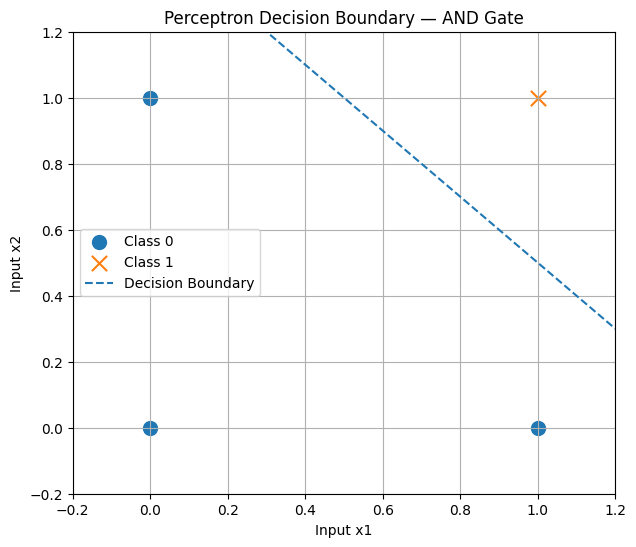

In [12]:
# Separate the two classes
class_0 = X[y == 0]
class_1 = X[y == 1]

plt.figure(figsize=(7, 6))

plt.scatter(
    class_0[:, 0], class_0[:, 1],
    label="Class 0", marker="o", s=100
)

plt.scatter(
    class_1[:, 0], class_1[:, 1],
    label="Class 1", marker="x", s=120
)

# Decision boundary:
# w1*x1 + w2*x2 + b = 0
x1_line = np.linspace(-0.2, 1.2, 100)
x2_line = -(
    model.weights[0] * x1_line + model.bias
) / model.weights[1]

plt.plot(
    x1_line, x2_line,
    linestyle="--",
    label="Decision Boundary"
)

plt.xlabel("Input x1")
plt.ylabel("Input x2")
plt.title("Perceptron Decision Boundary — AND Gate")
plt.xlim(-0.2, 1.2)
plt.ylim(-0.2, 1.2)
plt.grid(True)
plt.legend()
plt.show()

<h3> Step 5: Definition of the XOR dataset

<h4> The XOR Experiment and the Perceptron Limitation

In the previous experiment, we saw that a Perceptron can solve the AND problem with 100% accuracy. Now, we want to examine whether this same model can also learn the XOR problem.

In [13]:
# XOR dataset
X_xor = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
], dtype=float)

y_xor = np.array([0, 1, 1, 0], dtype=int)

print("Inputs:")
print(X_xor)

print("\nTargets:")
print(y_xor)

Inputs:
[[0. 0.]
 [0. 1.]
 [1. 0.]
 [1. 1.]]

Targets:
[0 1 1 0]


<h3> Step 6: Training the Perceptron

We do not modify the previous class. We simply train a new model on the XOR data.

In [14]:
xor_model = Perceptron(
    learning_rate=0.1,
    epochs=20
)

xor_model.fit(X_xor, y_xor)

xor_predictions = xor_model.predict(X_xor)

print("Learned weights:", xor_model.weights)
print("Learned bias:", xor_model.bias)

print("\nPredictions:", xor_predictions)
print("Targets:     ", y_xor)

print("\nErrors per epoch:", xor_model.errors_)

accuracy = np.mean(xor_predictions == y_xor)
print("Training accuracy:", accuracy)

Learned weights: [-0.1  0. ]
Learned bias: 0.09999999999999998

Predictions: [1 1 0 0]
Targets:      [0 1 1 0]

Errors per epoch: [2, 3, 3, 2, 3, 2, 2, 3, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4]
Training accuracy: 0.5


#### Why does the model fail?
AND: Linearly separable problem

The classes can be separated by a straight line; therefore, a single Perceptron is sufficient.

XOR: Non-linearly separable problem

Samples of class 0 are located in two diagonally opposite corners, while samples of class 1 are in the other two corners. No straight line can completely separate these two classes.

This limitation does not stem from insufficient training or an inadequate number of epochs; a perceptron with a linear decision boundary is fundamentally incapable of fully solving the XOR problem.

<h3> Step 7: XOR Plot and Decision Boundary

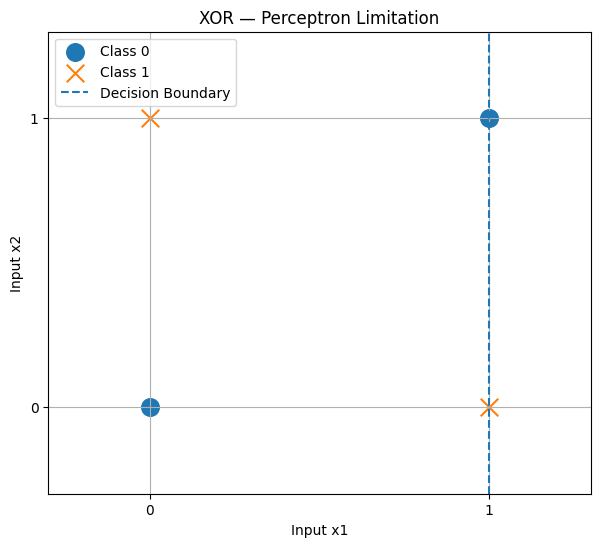

In [15]:
class_0 = X_xor[y_xor == 0]
class_1 = X_xor[y_xor == 1]

plt.figure(figsize=(7, 6))

plt.scatter(
    class_0[:, 0], class_0[:, 1],
    s=160, marker="o", label="Class 0"
)

plt.scatter(
    class_1[:, 0], class_1[:, 1],
    s=160, marker="x", label="Class 1"
)

# Plot the learned linear decision boundary
w1, w2 = xor_model.weights
bias = xor_model.bias

if abs(w2) > 1e-12:
    x1_line = np.linspace(-0.3, 1.3, 100)
    x2_line = -(w1 * x1_line + bias) / w2
    plt.plot(x1_line, x2_line, "--", label="Decision Boundary")
elif abs(w1) > 1e-12:
    boundary_x = -bias / w1
    plt.axvline(
        boundary_x,
        linestyle="--",
        label="Decision Boundary"
    )

plt.xlabel("Input x1")
plt.ylabel("Input x2")
plt.title("XOR — Perceptron Limitation")
plt.xticks([0, 1])
plt.yticks([0, 1])
plt.xlim(-0.3, 1.3)
plt.ylim(-0.3, 1.3)
plt.grid(True)
plt.legend()
plt.show()

The vertical line at $x_1=1$ indicates that the Perceptron has effectively come to depend on the first feature, and it cannot correctly separate the four XOR points using a linear boundary.

In the diagram, we can see that the samples of class zero are located in two diagonally opposite corners, while the samples of class one are in the other two corners; consequently, a straight line cannot separate these two classes.

#### Conclusion:

- AND: A perceptron with a linear decision boundary can solve the problem.
- XOR: A simple perceptron cannot fully solve the problem; doing so requires a network with a hidden layer and a non-linear activation function.

<h3> Step 8: Multilayer Perceptron Architecture (MLP)

Instead of a single neuron, we use a hidden layer with two neurons.

This network has two inputs, two hidden neurons, and one output. By using a non-linear activation function, the hidden layer can create different representations of the input; consequently, the network has the capacity to learn a relationship like XOR. Of course, simply constructing the network does not mean that the XOR problem is solved; the weights must also be trained.

Sigmoid activation function:

$\sigma(z)=\frac{1}{1+e^{-z}}$

<h3> Step 8.1: Forward Propagation

In [16]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Reproducible initialization
np.random.seed(42)

# Network architecture: 2 -> 2 -> 1
input_size = 2
hidden_size = 2
output_size = 1

# Weights and biases
W1 = np.random.randn(input_size, hidden_size) * 0.5
b1 = np.zeros((1, hidden_size))

W2 = np.random.randn(hidden_size, output_size) * 0.5
b2 = np.zeros((1, output_size))

# Forward propagation
Z1 = X_xor @ W1 + b1
A1 = sigmoid(Z1)

Z2 = A1 @ W2 + b2
Y_hat = sigmoid(Z2)

# Inspect intermediate results
print("W1 shape:", W1.shape)
print("b1 shape:", b1.shape)

print("Z1 shape:", Z1.shape)
print("A1 shape:", A1.shape)

print("W2 shape:", W2.shape)
print("b2 shape:", b2.shape)

print("Z2 shape:", Z2.shape)
print("Y_hat shape:", Y_hat.shape)

print("\nHidden layer activations:")
print(A1)

print("\nOutput probabilities:")
print(Y_hat)

print("\nPredicted classes:")
print((Y_hat >= 0.5).astype(int).ravel())

W1 shape: (2, 2)
b1 shape: (1, 2)
Z1 shape: (4, 2)
A1 shape: (4, 2)
W2 shape: (2, 1)
b2 shape: (1, 1)
Z2 shape: (4, 1)
Y_hat shape: (4, 1)

Hidden layer activations:
[[0.5        0.5       ]
 [0.58026084 0.68168255]
 [0.56177208 0.48272384]
 [0.63927097 0.66649678]]

Output probabilities:
[[0.47076524]
 [0.46313239]
 [0.4694675 ]
 [0.46185688]]

Predicted classes:
[0 0 0 0]


#### Analysis of Outputs

| Variable | Shape | Concept |
| -------- | ----- | ------- |
| W1       | (2, 2) | Input weights to the hidden layer |
| A1       | (4, 2) | Activations of two hidden neurons for four samples |
| W2       | (2, 1) | Weights from the hidden layer to the output |
| Y_hat    | (4, 1) | Predicted probability for each sample |

The initial probabilities are close to 0.5 because the weights have been randomly initialized, and we have not yet performed any training.

Important note: At this stage, we have only implemented forward propagation. We do not yet have a loss function, backpropagation, or weight updates.

<h3> Step 8.2: Loss Function

For a binary classification problem, we use Binary Cross-Entropy (BCE). This function measures the discrepancy between the actual label and the predicted probability.

Its formula is:

$L=-\frac{1}{N}\sum_{i=1}^{N}
\left[
y_i\log(\hat y_i)
+(1-y_i)\log(1-\hat y_i)
\right]$

- $y_i$: The actual label
- $\hat y_i$: The predicted probability
- $N$: The number of samples

In [17]:
# Binary Cross-Entropy Loss
y_true = y_xor.reshape(-1, 1)

# Avoid log(0)
epsilon = 1e-12
y_pred_clipped = np.clip(
    Y_hat,
    epsilon,
    1 - epsilon
)

# Calculate BCE
bce_loss = -np.mean(
    y_true * np.log(y_pred_clipped)
    + (1 - y_true) * np.log(1 - y_pred_clipped)
)

print("Targets shape:", y_true.shape)
print("Predictions shape:", Y_hat.shape)
print("Binary Cross-Entropy Loss:", bce_loss)

Targets shape: (4, 1)
Predictions shape: (4, 1)
Binary Cross-Entropy Loss: 0.6954631049425887


The Binary Cross-Entropy Loss value is 0.69546, which is close to

 $\ln(2) \approx 0.69315$. 
 
 This indicates that the network has not yet learned effectively, and its predictions are roughly equivalent to random guessing.

<h3> Step 8.3: Gradient Descent

Our goal is to find the weights that minimize the loss. The weight update rule is as follows:

$w_{\text{new}}=w_{\text{old}}-\eta\frac{\partial L}{\partial w}$

In this equation:
- $w$: A network weight
- $L$: The loss value
- $\eta$: The learning rate
- $\frac{\partial L}{\partial w}$: The gradient of the loss with respect to the weight

The gradient indicates the direction in which the loss increases; for this reason, in Gradient Descent, we move in the opposite direction.

For now, we will only modify the weight $W2[0, 0]$. To calculate the gradient, we will use the finite differences approximation method. This approach is useful for teaching the concept of a gradient; in the next step, we will calculate the gradients using backpropagation and the chain rule.

In [18]:
# Gradient Descent on one network weight
# using a numerical gradient approximation

def forward_with_params(X, W1, b1, W2, b2):
    Z1 = X @ W1 + b1
    A1 = sigmoid(Z1)

    Z2 = A1 @ W2 + b2
    Y_hat = sigmoid(Z2)

    return Y_hat


def calculate_bce(y_true, y_pred):
    eps = 1e-12
    y_pred = np.clip(y_pred, eps, 1 - eps)

    return -np.mean(
        y_true * np.log(y_pred)
        + (1 - y_true) * np.log(1 - y_pred)
    )


def loss_for_W2(candidate_W2):
    predictions = forward_with_params(
        X_xor, W1, b1, candidate_W2, b2
    )
    return calculate_bce(y_true, predictions)


# Current loss
loss_before = loss_for_W2(W2)

# Approximate gradient using central differences
epsilon = 1e-5

W2_plus = W2.copy()
W2_minus = W2.copy()

W2_plus[0, 0] += epsilon
W2_minus[0, 0] -= epsilon

gradient = (
    loss_for_W2(W2_plus) - loss_for_W2(W2_minus)
) / (2 * epsilon)

# Update a copy of the weight matrix
learning_rate = 0.1

W2_updated = W2.copy()
W2_updated[0, 0] -= learning_rate * gradient

loss_after = loss_for_W2(W2_updated)

print("Original weight:", W2[0, 0])
print("Numerical gradient:", gradient)
print("Updated weight:", W2_updated[0, 0])

print("\nLoss before update:", loss_before)
print("Loss after update:", loss_after)
print("Loss decreased:", loss_after < loss_before)

Original weight: -0.11707668736166799
Numerical gradient: -0.019731821032653585
Updated weight: -0.11510350525840263

Loss before update: 0.6954631049425887
Loss after update: 0.6954243292159099
Loss decreased: True


The reduction in loss is very small because, in this experiment, we have modified only one of the weights. The entire network has not yet been trained.

Important note: In this cell, we do not modify the original weight $W_2$; the update is performed on a copy so that we can examine its effect in isolation.

<h3> Step 8.4: Backpropagation

In forward propagation, we move from the input to the output. In backpropagation, we do the opposite: we calculate the output error and propagate its effect back to the preceding layers.

<h4> Calculating Gradients

In [19]:
# Backpropagation from scratch
# XOR dataset, network architecture: 2 -> 2 -> 1

# Step 1: Forward propagation
Z1 = X_xor @ W1 + b1
A1 = sigmoid(Z1)

Z2 = A1 @ W2 + b2
Y_hat = sigmoid(Z2)

N = X_xor.shape[0]

loss_before = calculate_bce(y_true, Y_hat)


# Step 2: Output layer gradients
# BCE combined with sigmoid output
dZ2 = (Y_hat - y_true) / N

dW2 = A1.T @ dZ2
db2 = np.sum(dZ2, axis=0, keepdims=True)


# Step 3: Hidden layer gradients
dA1 = dZ2 @ W2.T

dZ1 = dA1 * A1 * (1 - A1)

dW1 = X_xor.T @ dZ1
db1 = np.sum(dZ1, axis=0, keepdims=True)


# Step 4: Inspect gradient shapes
print("dW1 shape:", dW1.shape)
print("db1 shape:", db1.shape)
print("dW2 shape:", dW2.shape)
print("db2 shape:", db2.shape)

print("\nAnalytical gradient for W2[0, 0]:", dW2[0, 0])
print("Numerical gradient for W2[0, 0]:", gradient)
print(
    "Absolute difference:",
    abs(dW2[0, 0] - gradient)
)

dW1 shape: (2, 2)
db1 shape: (1, 2)
dW2 shape: (2, 1)
db2 shape: (1, 1)

Analytical gradient for W2[0, 0]: -0.019731821039193922
Numerical gradient for W2[0, 0]: -0.019731821032653585
Absolute difference: 6.540337715854605e-12


In the previous cell, we calculated the gradient of $W2[0, 0]$ using the numerical gradient method. Now, we will obtain the same gradient using backpropagation.

These two values ​​are very close to each other; the difference is small, on the order of numerical error.

<h4> Updating all parameters (weights and bias)

In [20]:
learning_rate = 0.1

# Update all weights and biases
W1_new = W1 - learning_rate * dW1
b1_new = b1 - learning_rate * db1

W2_new = W2 - learning_rate * dW2
b2_new = b2 - learning_rate * db2


# Evaluate updated parameters
Y_hat_new = forward_with_params(
    X_xor,
    W1_new,
    b1_new,
    W2_new,
    b2_new
)

loss_after = calculate_bce(y_true, Y_hat_new)

print("Loss before update:", loss_before)
print("Loss after update:", loss_after)
print("Loss decreased:", loss_after < loss_before)

Loss before update: 0.6954631049425887
Loss after update: 0.6952753749484086
Loss decreased: True


<h3> Step 9: Training Loop

At this stage, we perform four tasks in each iteration:

1. Executing forward propagation
2. Calculating the binary cross-entropy loss
3. Executing backpropagation to compute the gradients
4. Updating all weights and biases using gradient descent

Note: While the XOR problem can be solved using two hidden neurons, the previous random initialization might have caused the training to get stuck at an unfavorable point. For this experiment, we initialize the network using a new seed to ensure the learning process is reproducible.

In [21]:
# Full MLP training loop for XOR
# Architecture: 2 -> 2 -> 1

np.random.seed(1)

input_size = 2
hidden_size = 2
output_size = 1

# Initialize parameters
W1 = np.random.randn(input_size, hidden_size) * 0.5
b1 = np.zeros((1, hidden_size))

W2 = np.random.randn(hidden_size, output_size) * 0.5
b2 = np.zeros((1, output_size))

learning_rate = 1.0
epochs = 10_000
N = X_xor.shape[0]

loss_history = []

for epoch in range(epochs):

    # 1. Forward propagation
    Z1 = X_xor @ W1 + b1
    A1 = sigmoid(Z1)

    Z2 = A1 @ W2 + b2
    Y_hat = sigmoid(Z2)

    # 2. Calculate loss
    loss = calculate_bce(y_true, Y_hat)
    loss_history.append(loss)

    # 3. Backpropagation: output layer
    dZ2 = (Y_hat - y_true) / N

    dW2 = A1.T @ dZ2
    db2 = np.sum(dZ2, axis=0, keepdims=True)

    # 4. Backpropagation: hidden layer
    dA1 = dZ2 @ W2.T
    dZ1 = dA1 * A1 * (1 - A1)

    dW1 = X_xor.T @ dZ1
    db1 = np.sum(dZ1, axis=0, keepdims=True)

    # 5. Update all parameters
    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1

    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2


# Final forward pass
Z1 = X_xor @ W1 + b1
A1 = sigmoid(Z1)

Z2 = A1 @ W2 + b2
Y_hat = sigmoid(Z2)

predictions = (Y_hat >= 0.5).astype(int)

final_loss = calculate_bce(y_true, Y_hat)
accuracy = np.mean(predictions == y_true)

print("Initial loss:", loss_history[0])
print("Final loss:", final_loss)

print("\nPredicted probabilities:")
print(Y_hat.ravel().round(4))

print("\nPredictions:", predictions.ravel())
print("Targets:    ", y_xor)

print("\nTraining accuracy:", accuracy)
print("Training epochs:", epochs)

Initial loss: 0.6993987515397051
Final loss: 0.0009863868432955852

Predicted probabilities:
[8.000e-04 9.991e-01 9.991e-01 1.300e-03]

Predictions: [0 1 1 0]
Targets:     [0 1 1 0]

Training accuracy: 1.0
Training epochs: 10000


The network has not only correctly predicted the classes, but its output probabilities have also reached values ​​close to 0 and 1.

The loss has decreased from 0.6994 to 0.000986; this means the network has adjusted its weights so that its predictions align with the actual labels.

However, we only have four samples here; therefore, while this result demonstrates that the network has learned the XOR function, it does not necessarily guarantee that it will perform well on real-world, complex data.

<h3> Step 10: Loss Chart

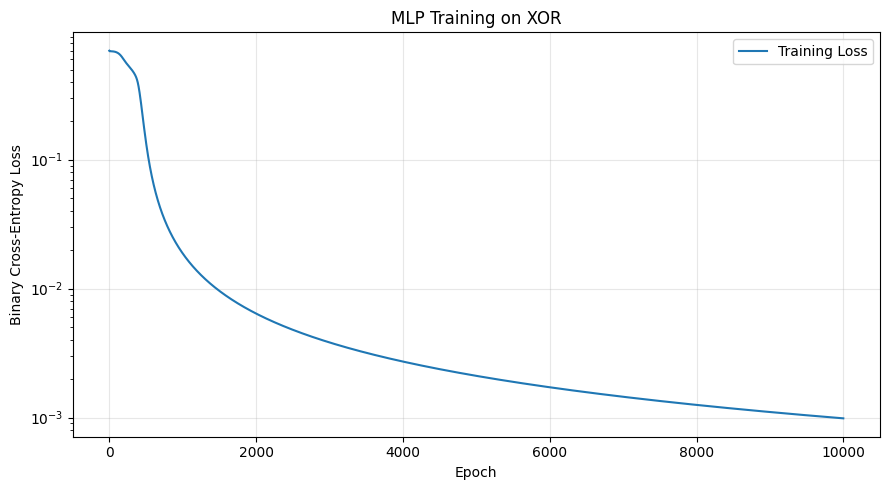

In [22]:
plt.figure(figsize=(9, 5))

plt.plot(loss_history, label="Training Loss")

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("MLP Training on XOR")

plt.yscale("log")
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

We have used a logarithmic scale for the loss axis so that the reduction in the error value—from approximately 0.7 to less than 0.001—can be seen more clearly.

### Analysis of the Loss Plot

- Start of training: The loss value is approximately 0.699; the network has not yet learned the XOR pattern.
- Initial rapid decline: During the early stages of training, the loss decreases quickly; the weights are learning the structure of the problem.
- Gradual decline: Subsequently, the loss decreases more slowly as the network refines its predictions.
- End of training: The loss reaches approximately 0.000986, and all four samples are correctly classified.

The vertical axis is logarithmic; therefore, the gradual decline toward the end of the plot remains clearly visible.

Note: Since the XOR problem consists of only four samples, this experiment is suitable for demonstrating the learning mechanism, but it does not serve as a benchmark for evaluating generalization to real-world data.

<h3> Step 11: MLP Nonlinear Decision Boundary

In a Perceptron, we had a straight line; however, an MLP network with a hidden layer and non-linear activation can create more complex decision regions.

This code uses the same trained weights and calculates the probability of class one at different points in the input space. The boundary line shows the points where the probability of predicting class one is equal to 0.5.

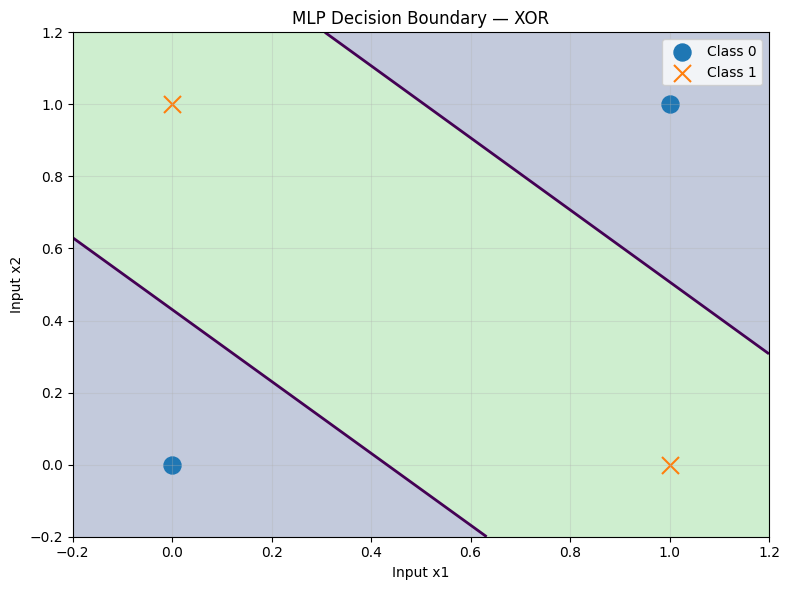

In [23]:
# Create a dense grid over the input space
x1_values = np.linspace(-0.2, 1.2, 300)
x2_values = np.linspace(-0.2, 1.2, 300)

xx, yy = np.meshgrid(x1_values, x2_values)

grid = np.column_stack([
    xx.ravel(),
    yy.ravel()
])

# Forward propagation using trained parameters
hidden = sigmoid(grid @ W1 + b1)
probabilities = sigmoid(hidden @ W2 + b2)

probabilities = probabilities.reshape(xx.shape)

# Plot decision regions and boundary
plt.figure(figsize=(8, 6))

plt.contourf(
    xx, yy, probabilities,
    levels=[0, 0.5, 1],
    alpha=0.3
)

plt.contour(
    xx, yy, probabilities,
    levels=[0.5],
    linewidths=2
)

# Plot original XOR samples
plt.scatter(
    X_xor[y_xor == 0, 0],
    X_xor[y_xor == 0, 1],
    s=150,
    marker="o",
    label="Class 0"
)

plt.scatter(
    X_xor[y_xor == 1, 0],
    X_xor[y_xor == 1, 1],
    s=150,
    marker="x",
    label="Class 1"
)

plt.xlabel("Input x1")
plt.ylabel("Input x2")
plt.title("MLP Decision Boundary — XOR")

plt.xlim(-0.2, 1.2)
plt.ylim(-0.2, 1.2)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

Now we can see the key difference: a Perceptron, with its linear decision boundary, could not solve the XOR problem, whereas an MLP with a hidden layer was able to correctly classify all four samples. With this, our section on the fundamentals of neural networks is complete in terms of its core implementation.

### Implementation Summary:

- Perceptron: Neuron, weights, bias, and learning rule.
- Linear Classification: Understanding the limitations of a linear decision boundary via the XOR problem.
- Forward Propagation: Computing the output of a multi-layer network.
- Binary Cross-Entropy: Measuring prediction error.
- Gradient Descent: Updating parameters to minimize the loss.
- Backpropagation: Calculating gradients using the chain rule and verifying them via numerical gradients.
- Training Loop: Integrating all components to train the network.